# Predicting Procrastination Based on Screen Time, Sleep Patterns and Lifestyle Factors

This project predicts the numerical `procrastination_score` using 20 selected screen-time, sleep and lifestyle predictors. It compares Linear Regression implemented from scratch with Random Forest Regressor.

**Dataset requirement:** keep `procrastination_survey_dataset.csv` in the same folder as this notebook.

The test set is reserved for the final evaluation. Model configurations are compared using five-fold cross-validation on the training set.

The dataset metadata marks the records as synthetic, so results should not be treated as evidence of predictive accuracy on real-world populations.

## 1. Load and verify the CSV

The first cells inspect the CSV structure and verify the extra-field pattern before correcting affected rows.

In [1]:
import csv
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from sklearn.ensemble import RandomForestRegressor

random_seed = 42
np.random.seed(random_seed)


In [2]:


dataset_path = "procrastination_survey_dataset.csv"
target_column = "procrastination_score"


with open(dataset_path, "r", encoding = "utf-8-sig", newline = "") as f:
    csv_rows = list(csv.reader(f))

if not csv_rows:
    raise ValueError ("CSV file not found/empty")



# COLUMN NAMES
header = csv_rows[0]

# (IGNORE BLANK ROWS)
raw_data_rows = [ row for row in csv_rows[1:] if row]
blank_rows_count = len(csv_rows) - len(raw_data_rows) -1

# Expected nº of fields from header
expected_column_count = len(header)

print (f"\nExpected columns from the header: {expected_column_count}")
print (f"\nNon-empty data rows: {len(raw_data_rows)}")
print (f"\nBlank rows left out: {blank_rows_count}\n")


# Counting number of fields in every non-empty data row

row_width_counts = (pd.Series([len(row) for row in raw_data_rows])
                    .value_counts()
                    .sort_index())
    

print (f"\n\nObserved row widths: ")
for field_count, row_count in row_width_counts.items():
    print (f"Rows with {field_count} fields: {row_count}")
print ("\n")

# rows shorter/longer than header
short_rows = [row for row in raw_data_rows
            if len(row) < expected_column_count]
    

overlong_widths = sorted({len(row)
                        for row in raw_data_rows
                        if len(row) > expected_column_count})
    

if short_rows:
    raise ValueError ("Some rows contain fewer fuelds than the header")
if len(overlong_widths) >1:
    raise ValueError ("Several different overlong row widths were found")

# Checking for extra fields
extra_field_count = (overlong_widths[0] - expected_column_count
                     if overlong_widths else 0)

print (f"\nExtra fields per affected row: {extra_field_count}")


# Derive the position of planning_style from the actual header
if "planning_style" not in header:
    raise ValueError("The expected planning_style column is missing.")

planning_style_index = header.index("planning_style")

correctly_aligned_rows = [
    row for row in raw_data_rows
    if len (row) == expected_column_count
]

overlong_rows = [
    row for row in raw_data_rows
    if len(row) > expected_column_count
]


# values = numbers?
def is_numeric_value(value):
    converted_value = pd.to_numeric(
        value,
        errors="coerce"
    )

    return pd.notna(converted_value)


# Inspect the planning_style position in correctly aligned rows
correct_style_text_count = sum(
    isinstance(row[planning_style_index], str)
    and bool(row[planning_style_index].strip())
    and not is_numeric_value(row[planning_style_index])
    for row in correctly_aligned_rows
)

print(
    "\nNon-empty textual values at the planning_style position "
    "in correctly aligned rows:",
    correct_style_text_count
)

# Check whether the extra field appears immediately before planning_style
if extra_field_count > 0:

    numeric_at_expected_position = sum(
        is_numeric_value(row[planning_style_index])
        for row in overlong_rows
    )

    shifted_style_text_count = sum(
        isinstance(
            row[planning_style_index + extra_field_count],
            str
        )
        and bool(
            row[planning_style_index + extra_field_count].strip()
        )
        and not is_numeric_value(
            row[planning_style_index + extra_field_count]
        )
        for row in overlong_rows
    )

    print(
        "Affected rows with a numeric value at the expected "
        "planning_style position:",
        numeric_at_expected_position
    )

    print(
        "Affected rows with a textual value after skipping "
        "the extra fields:",
        shifted_style_text_count
    )

    # Correct only if the observed structure supports this decision
    repair_pattern_verified = (
        correct_style_text_count == len(correctly_aligned_rows)
        and numeric_at_expected_position == len(overlong_rows)
        and shifted_style_text_count == len(overlong_rows)
        and len(overlong_rows) > 0
    )

    if not repair_pattern_verified:
        raise ValueError(
            "The extra-field pattern could not be verified. "
            "Inspect the CSV before attempting a correction."
        )

    print("\nThe extra-field pattern was verified.")

else:
    print("\nNo overlong data rows require correction.")


# which participant rows are corrected
repaired_participant_ids = []


def repair_extra_field(row):
    """
    Remove an extra field only when its position and type
    match the structure verified above.
    """

    if (
        extra_field_count > 0
        and len(row) == expected_column_count + extra_field_count
    ):

        expected_style_value = row[
            planning_style_index + extra_field_count
        ]

        if (
            is_numeric_value(row[planning_style_index])
            and isinstance(expected_style_value, str)
            and expected_style_value.strip()
            and not is_numeric_value(expected_style_value)
        ):

            participant_index = header.index("participant_id")

            repaired_participant_ids.append(
                row[participant_index]
            )

            # Remove the extra field using the derived index
            return (
                row[:planning_style_index]
                + row[planning_style_index + extra_field_count:]
            )

    raise ValueError(
        "An overlong row does not match the verified repair pattern."
    )


# Let Pandas handle the data types after the structural check
bad_line_handler = (
    repair_extra_field
    if extra_field_count > 0
    else "error"
)



Expected columns from the header: 68

Non-empty data rows: 300

Blank rows left out: 7



Observed row widths: 
Rows with 68 fields: 65
Rows with 69 fields: 235



Extra fields per affected row: 1

Non-empty textual values at the planning_style position in correctly aligned rows: 65
Affected rows with a numeric value at the expected planning_style position: 235
Affected rows with a textual value after skipping the extra fields: 235

The extra-field pattern was verified.


## 2. Explore the dataset

Load the corrected CSV, inspect dimensions, data types, missing values, duplicates and numerical statistics. The following cell also calculates the target range and displays its distribution.


Loaded dataset shape: (300, 68)
Corrected rows: 235
Rows: 300
Columns: 68

Column names:
['participant_id', 'data_source', 'synthetic_flag', 'age', 'age_group', 'gender', 'education_level', 'employment_status', 'occupation_category', 'average_sleep_hours', 'sleep_quality', 'daily_screen_time_hours', 'daily_social_media_hours', 'physical_activity_frequency', 'work_hours_per_day', 'study_hours_per_day', 'commute_hours_per_day', 'perceived_workload', 'task_type', 'task_importance', 'task_difficulty', 'task_interest', 'task_anxiety', 'task_clarity', 'task_complexity', 'task_duration_estimate_hours', 'deadline_days_remaining', 'P01', 'P02', 'P03', 'P04', 'P05', 'P06', 'P07', 'P08', 'P09', 'P10', 'S01', 'S02', 'S03', 'S04', 'S05', 'S06', 'S07', 'S08', 'S09', 'S10', 'planning_style', 'scheduling_method', 'primary_social_platform', 'social_media_check_frequency', 'social_media_during_work_or_study', 'social_media_as_task_avoidance', 'notifications_enabled', 'primary_procrastination_trigger', 

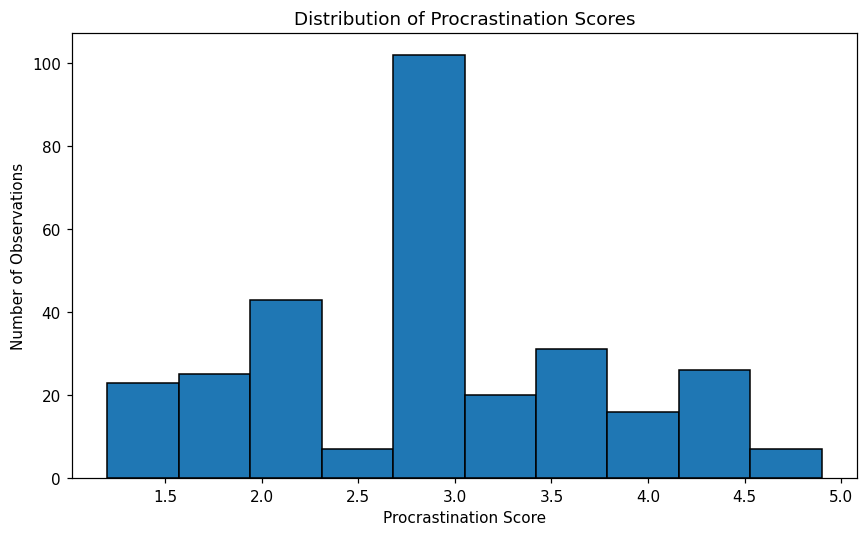

In [3]:


df = pd.read_csv(
    dataset_path,
    encoding="utf-8-sig",
    engine="python",
    on_bad_lines=bad_line_handler
)

print("\nLoaded dataset shape:", df.shape)
print("Corrected rows:", len(repaired_participant_ids))


# Nº of rows and columns
print("Rows:", df.shape[0])
print("Columns:", df.shape[1])

# Column names and data types
print("\nColumn names:")
print(df.columns.tolist())

print("\nData types and non-null counts:")
df.info()

# Missing values per column
missing_values = df.isnull().sum()
missing_columns = missing_values[missing_values > 0]

print(f"\nColumns with missing values: {missing_columns}")

# Duplicates
print (f"\nDuplicate complete rows: {df.duplicated().sum()}")
print (f"Duplicate participant ID's: {df["participant_id"].duplicated().sum()}")


# Feature's values statistics
print (f"\nNumerical descriptive statistics: ")
print (df.describe(include=[np.number]).T.round(1))

# Target range and distribution
target_values = pd.to_numeric(df[target_column], errors="coerce")
print("\nTarget range:", target_values.min(), "to", target_values.max())
print("Distinct target values:", target_values.nunique())

plt.figure(figsize=(8, 5))
plt.hist(target_values.dropna(), bins="auto", edgecolor="black")
plt.title("Distribution of Procrastination Scores")
plt.xlabel("Procrastination Score")
plt.ylabel("Number of Observations")
plt.tight_layout()
plt.show()


### First 30 rows

In [4]:
pd.set_option("display.max_columns", None)
df.head(30)


,participant_id,data_source,synthetic_flag,age,age_group,gender,education_level,employment_status,occupation_category,average_sleep_hours,sleep_quality,daily_screen_time_hours,daily_social_media_hours,physical_activity_frequency,work_hours_per_day,study_hours_per_day,commute_hours_per_day,perceived_workload,task_type,task_importance,task_difficulty,task_interest,task_anxiety,task_clarity,task_complexity,task_duration_estimate_hours,deadline_days_remaining,P01,P02,P03,P04,P05,P06,P07,P08,P09,P10,S01,S02,S03,S04,S05,S06,S07,S08,S09,S10,planning_style,scheduling_method,primary_social_platform,social_media_check_frequency,social_media_during_work_or_study,social_media_as_task_avoidance,notifications_enabled,primary_procrastination_trigger,stress_rating,mood_rating,energy_rating,concentration_difficulty,feeling_overwhelmed_frequency,work_life_balance,perceived_control,procrastination_score,scheduling_score,task_anxiety_score,workload_score,social_media_avoidance_score,wellbeing_score
0,P0001,synthetic_ai,1,19,18-20,Male,Undergraduate,Student,Education,6.5,Fair,7.0,3.5,1-2x/week,0.0,5.0,0.5,Moderate,Exam preparation,5,4,2,4,3,4,6.0,7,4,4,3,4,3,4,4,5,3,4,2,3,2,2,3,2,2,3,4,2,Deadline-driven,Mental planning,Instagram,Every few hours,Often,4,Yes,Low motivation,7,5,4,6,6,5,4,3.8,2.6,4.00,2.19,4.00,4.2
1,P0002,synthetic_ai,1,34,30-39,Female,Postgraduate,Full-time employed,Healthcare,7.0,Good,6.5,1.5,3-4x/week,9.0,0.5,1.0,Heavy,Work project,5,4,3,3,4,4,8.0,5,3,3,2,3,2,3,3,3,2,3,4,4,3,4,4,4,3,4,3,2,Weekly planner,Phone calendar,LinkedIn,Once a day,Rarely,2,Yes,Fatigue,7,6,5,4,6,5,5,2.8,3.6,3.67,3.28,2.33,5.5
2,P0003,synthetic_ai,1,22,21-24,Female,Undergraduate,Student,Education,6.0,Poor,9.0,5.0,Never,0.0,6.0,0.0,Moderate,Academic assignment,4,3,2,4,2,3,4.0,3,5,5,4,5,4,4,3,5,3,4,2,2,2,2,2,2,2,4,4,1,Reactive planning,Mental planning,TikTok,Constantly,Often,5,Yes,Social media,8,4,3,7,7,4,3,4.2,2.1,3.33,1.88,4.67,3.6
3,P0004,synthetic_ai,1,45,40-49,Male,Undergraduate,Full-time employed,Technology,7.5,Good,8.0,2.0,3-4x/week,9.0,0.0,1.5,Heavy,Work project,5,5,3,4,3,5,10.0,10,3,4,3,3,3,3,4,4,3,4,4,3,4,4,4,4,3,4,3,2,Weekly planner,Computer calendar,LinkedIn,2-3 times a day,Sometimes,3,Yes,Task difficulty,6,6,6,5,5,6,6,3.4,3.6,4.33,3.28,3.00,5.8
4,P0005,synthetic_ai,1,28,25-29,Non-binary,Postgraduate,Full-time employed,Research,6.5,Fair,7.5,2.5,1-2x/week,8.0,1.5,0.5,Heavy,Work project,4,4,3,3,3,4,7.0,14,3,3,3,3,3,3,3,3,3,3,3,3,3,3,3,3,3,3,3,3,Mixed strategy,Todo application,Reddit,2-3 times a day,Sometimes,3,No,Lack of clarity,6,6,6,5,5,6,5,3.0,3.0,3.67,2.94,3.00,5.4
5,P0006,synthetic_ai,1,62,60+,Female,Undergraduate,Retired,Other,8.0,Good,3.5,0.5,Daily,0.0,0.0,0.0,Very light,Household task,3,2,4,1,4,2,2.0,30,2,1,2,2,2,2,1,1,2,2,4,3,3,4,4,3,4,3,2,2,Daily planner,Paper notebook,Facebook,Once a day,Never,1,No,Boredom,3,8,7,2,2,8,8,1.8,3.6,1.67,1.00,1.33,7.8
6,P0007,synthetic_ai,1,25,25-29,Male,Undergraduate,Full-time employed,Finance,6.0,Fair,8.0,2.0,1-2x/week,8.5,0.0,1.0,Heavy,Financial task,4,3,2,3,3,3,5.0,7,3,4,3,4,3,3,3,4,3,4,3,3,3,3,4,3,3,3,3,3,Daily planner,Phone calendar,Instagram,Every few hours,Sometimes,3,Yes,Boredom,7,5,5,5,6,5,5,3.4,3.1,3.00,3.09,3.00,5.1
7,P0008,synthetic_ai,1,31,30-39,Female,Postgraduate,Self-employed,Creative,7.0,Good,7.0,3.0,3-4x/week,6.0,1.0,0.0,Moderate,Personal project,3,3,4,2,3,3,5.0,21,2,2,3,2,3,3,2,2,3,2,4,4,3,4,4,4,4,3,2,3,Weekly planner,Todo application,Instagram,2-3 times a day,Rarely,2,Yes,Perfectionism,4,7,7,3,3,7,7,2.5,3.7,2.67,2.25,2.33,7.2
8,P0009,synthetic_ai,1,20,18-20,Male,High school,Student,Education,6.0,Poor,10.0,5.5,Never,2.0,4.0,0.0,Moderate,Exam preparation,5,4,2,5,2,4,5.0,2,5,5,5,5,4,5,5,5,4,5,1,1,1,1,1,1,1,1,5,1,Reactive planning,Mental planning,YouTube,Constantly,Always,5,Yes,Entertainment,9,3,3,8,8,3,2,4.8,1.5,4.33,2.19,4.67,2.6
9,P0010,synthetic_ai,1,52,50-59,Male,Postgraduate,Full-time employed,Government,7.5,Good,5.0,1.0,3-4x/week,8.0,0.0,1.5,Heavy,Email/administrative task,3,2,2,2,4,2,2.0

## 3. Check categories and unusual values

The category counts help inspect categorical values. The next checks look for impossible daily-hour values and inconsistencies between related time variables. Potential unusual values are inspected but not automatically removed.

In [5]:
# 1.3- CATEGORIES AND INCONSISTENCIES
# --------------------------------------------------------------------------

# Display the categories and their frequencies.
text_columns = [
    column
    for column in df.select_dtypes(
        include=["object", "string"]
    ).columns
    if column != "participant_id"
]

for column in text_columns:
    print(f"\nCategories in {column}:")
    print(df[column].value_counts(dropna=False))

    print("\n"*3)



Categories in data_source:
data_source
synthetic_ai    300
Name: count, dtype: int64





Categories in age_group:
age_group
30-39    65
40-49    57
25-29    52
21-24    41
50-59    35
60+      27
18-20    23
Name: count, dtype: int64





Categories in gender:
gender
Female        152
Male          145
Non-binary      3
Name: count, dtype: int64





Categories in education_level:
education_level
Undergraduate    151
Postgraduate      85
High school       32
Diploma           18
Doctoral          10
Doctorate          4
Name: count, dtype: int64





Categories in employment_status:
employment_status
Full-time employed     184
Student                 51
Retired                 26
Freelancer              11
Self-employed           10
Part-time employed      10
Job seeker               6
Homemaker/caregiver      2
Name: count, dtype: int64





Categories in occupation_category:
occupation_category
Education        65
Healthcare       34
Technology       34
Other            34
Finance 

In [6]:


# Checking for values surpassing 24 hours
hours = 24

per_day_features = [
    "average_sleep_hours",
    "daily_screen_time_hours",
    "daily_social_media_hours",
    "work_hours_per_day",
    "study_hours_per_day",
    "commute_hours_per_day"
]

per_day_features = [
    column
    for column in per_day_features
    if column in df.columns
]

print("Checks for daily-hour variables:")

for column in per_day_features:

    values = pd.to_numeric(df[column], errors="coerce")

    outside_day = (
        (values < 0)
        | (values > hours)
    ).sum()

    invalid_numeric_values = (
        df[column].notna() & values.isna()
    ).sum()

    print(
        f"{column}: "
        f"minimum={values.min()}, "
        f"maximum={values.max()}, "
        f"outside physical limits={outside_day}, "
        f"non-numeric values={invalid_numeric_values}"
    )


# Checking inconsistencies between social-media time and total screen time
if {
    "daily_social_media_hours",
    "daily_screen_time_hours"
}.issubset(df.columns):

    social_media_time = pd.to_numeric(
        df["daily_social_media_hours"],
        errors="coerce"
    )

    screen_time = pd.to_numeric(
        df["daily_screen_time_hours"],
        errors="coerce"
    )

    print(
        "\nRows where social-media time exceeds screen time:",
        (social_media_time > screen_time).sum()
    )


# Check whether work, study and commuting fit within a day
time_columns = [
    "work_hours_per_day",
    "study_hours_per_day",
    "commute_hours_per_day"
]

if set(time_columns).issubset(df.columns):

    daily_commitments = df[time_columns].sum(axis=1)

    print(
        "Rows where work, study and commuting exceed "
        "the hours in a day:",
        (daily_commitments > hours).sum()
    )


# Inspect the observed scale of questionnaire items
procrastination_item_columns = [
    column
    for column in df.columns
    if column.startswith("P") and column[1:].isdigit()
]

if procrastination_item_columns:

    p_items = df[procrastination_item_columns].apply(
        pd.to_numeric,
        errors="coerce"
    )

    item_minimum = p_items.min().min()
    item_maximum = p_items.max().max()

    target_values = pd.to_numeric(
        df[target_column],
        errors="coerce"
    )

    outside_item_range = (
        (target_values < item_minimum)
        | (target_values > item_maximum)
    ).sum()

    print("\nObserved range of the P-Set items:")
    print (f"Minimum: {item_minimum}")
    print (f"Maximum: {item_maximum}")

    print(
        "Target scores outside the observed item range:",
        outside_item_range
    )


Checks for daily-hour variables:
average_sleep_hours: minimum=5.5, maximum=8.5, outside physical limits=0, non-numeric values=0
daily_screen_time_hours: minimum=2.5, maximum=11.0, outside physical limits=0, non-numeric values=0
daily_social_media_hours: minimum=0.5, maximum=6.0, outside physical limits=0, non-numeric values=0
work_hours_per_day: minimum=0.0, maximum=10.0, outside physical limits=0, non-numeric values=0
study_hours_per_day: minimum=0.0, maximum=6.0, outside physical limits=0, non-numeric values=0
commute_hours_per_day: minimum=0.0, maximum=1.5, outside physical limits=0, non-numeric values=0

Rows where social-media time exceeds screen time: 0
Rows where work, study and commuting exceed the hours in a day: 0

Observed range of the P-Set items:
Minimum: 1
Maximum: 5
Target scores outside the observed item range: 0


## 4. Select predictors and prepare the target

The project uses 20 predictors related to screen time, sleep, digital habits, daily routines and lifestyle. IDs, metadata, direct questionnaire items and other derived scores are excluded from the predictors.

In [7]:

print ("DATA PREPARATION", "-"*30)

# Predictors connected to screen time, sleep and lifestyle
feature_columns = [
    # Screen time
    "daily_screen_time_hours",
    "daily_social_media_hours",

    # Sleep
    "average_sleep_hours",
    "sleep_quality",

    # Lifestyle and daily routine
    "physical_activity_frequency",
    "work_hours_per_day",
    "study_hours_per_day",
    "commute_hours_per_day",

    # Digital habits
    "social_media_check_frequency",
    "social_media_during_work_or_study",
    "social_media_as_task_avoidance",
    "notifications_enabled",

    # Planning and wellbeing
    "planning_style",
    "stress_rating",
    "mood_rating",
    "energy_rating",
    "concentration_difficulty",
    "feeling_overwhelmed_frequency",
    "work_life_balance",
    "perceived_control"
]


print (f"Selected predictors: {len(feature_columns)}")
print (f"Target: {target_column}")

print (f"\nSelected feature names: {feature_columns}")


# Explicitly identify columns excluded from modelling
excluded_columns = sorted(
    set(df.columns)
    - set(feature_columns)
    - {target_column}
)

print("\nColumns excluded from modelling:")
print(excluded_columns)

# Identify direct questionnaire items and derived score columns
direct_questionnaire_items = [
    column
    for column in df.columns
    if (
        column.startswith("P")
        or column.startswith("S")
    )
    and column[1:].isdigit()
]

derived_score_columns = [
    column
    for column in df.columns
    if column.endswith("_score")
    and column != target_column
]

print("\nDirect questionnaire items excluded:")
print(direct_questionnaire_items)

print("\nOther derived scores excluded:")
print(derived_score_columns)


model_data = df[
    feature_columns + [target_column]
].copy()

# Check missing values only in the columns required for modelling
missing_model_values = model_data.isnull().sum()

print("\nMissing values in selected columns:")
print(
    missing_model_values[missing_model_values > 0]
    if missing_model_values.any()
    else "None"
)

# Remove incomplete modelling records, if any
rows_before_cleaning = len(model_data)

model_data = model_data.dropna(
    subset=feature_columns + [target_column]
)

rows_removed = rows_before_cleaning - len(model_data)

print("\nRows before cleaning:", rows_before_cleaning)
print("Rows removed:", rows_removed)
print("Rows remaining:", len(model_data))

# Separate predictors and target
x_raw = model_data[feature_columns].copy()

y = pd.to_numeric(
    model_data[target_column],
    errors="raise"
).astype(float)

print("\nPredictor matrix shape:", x_raw.shape)
print("Target shape:", y.shape)


DATA PREPARATION ------------------------------
Selected predictors: 20
Target: procrastination_score

Selected feature names: ['daily_screen_time_hours', 'daily_social_media_hours', 'average_sleep_hours', 'sleep_quality', 'physical_activity_frequency', 'work_hours_per_day', 'study_hours_per_day', 'commute_hours_per_day', 'social_media_check_frequency', 'social_media_during_work_or_study', 'social_media_as_task_avoidance', 'notifications_enabled', 'planning_style', 'stress_rating', 'mood_rating', 'energy_rating', 'concentration_difficulty', 'feeling_overwhelmed_frequency', 'work_life_balance', 'perceived_control']

Columns excluded from modelling:
['P01', 'P02', 'P03', 'P04', 'P05', 'P06', 'P07', 'P08', 'P09', 'P10', 'S01', 'S02', 'S03', 'S04', 'S05', 'S06', 'S07', 'S08', 'S09', 'S10', 'age', 'age_group', 'data_source', 'deadline_days_remaining', 'education_level', 'employment_status', 'gender', 'occupation_category', 'participant_id', 'perceived_workload', 'primary_procrastination_tri

## 5. Split into training and test sets

The split uses 80% of the usable observations for training and 20% for the final test. No fixed random seed is used, so the split and numerical results may vary between runs.

In [8]:

# Proportion 80-20
test_perc = 0.20


indices = np.random.permutation(len(x_raw))
test_size = int(np.ceil(test_perc * len(x_raw)))

if test_size <= 0 or test_size >= len(x_raw):
    raise ValueError("The train/test split is not valid.")

test_indices = indices[:test_size]
train_indices = indices[test_size:]


x_train_raw = x_raw.iloc[train_indices].copy()
x_test_raw = x_raw.iloc[test_indices].copy()

# Separate the target variable
y_train = y.iloc[train_indices].to_numpy(dtype=float)
y_test = y.iloc[test_indices].to_numpy(dtype=float)

# Display the resulting dataset sizes
print(f"\n\nTotal observations: {len(x_raw)}")
print(f"Training observations: {len(x_train_raw)}")
print(f"Testing observations: {len(x_test_raw)}\n\n")



print (f"Training proportion: {round(len(x_train_raw) / len(x_raw), 4)}")
print (f"Testing proportion: {round(len(x_test_raw) / len(x_raw), 4)}\n\n")




Total observations: 300
Training observations: 240
Testing observations: 60


Training proportion: 0.8
Testing proportion: 0.2




## 6. Preprocessing for cross-validation

Categorical variables are encoded using the categories available in each training fold. Numeric variables are standardized for Linear Regression using statistics from that fold's training portion only. Random Forest uses the encoded features without scaling.

In [9]:


def prepare_features(train_raw, other_raw):

    train_data = train_raw.copy()
    other_data = other_raw.copy()

    categorical_columns = train_data.select_dtypes(
        include = ["object", "string", "category"]
    ).columns.tolist()

    numerical_columns = train_data.select_dtypes(
        include = np.number
    ).columns.tolist()

    for column in categorical_columns:

        categories = train_data[column].dropna().unique().tolist()

        train_data[column] = pd.Categorical(
            train_data[column],
            categories=categories
        )

        other_data[column] = pd.Categorical(
            other_data[column],
            categories=categories
        )

    train_encoded = pd.get_dummies(
        train_data,
        columns = categorical_columns,
        drop_first = True,
        dtype=float
    )

    other_encoded = pd.get_dummies(
        other_data,
        columns = categorical_columns,
        drop_first = True,
        dtype=float
    )

    other_encoded = other_encoded.reindex(
        columns = train_encoded.columns,
        fill_value = 0
    )

    train_lr = train_encoded.copy()
    other_lr = other_encoded.copy()

    train_means = train_lr[numerical_columns].mean()
    train_stds = train_lr[numerical_columns].std(ddof=0)

    train_stds = train_stds.replace(0, 1)

    train_lr[numerical_columns] = (
        train_lr[numerical_columns] - train_means
    ) / train_stds

    other_lr[numerical_columns] = (
        other_lr[numerical_columns] - train_means
    ) / train_stds

    return train_encoded, other_encoded, train_lr, other_lr


## 7. Linear Regression implemented from scratch

The model calculates predictions as a weighted sum of the input features. It uses gradient descent to update the coefficients. No ready-made Linear Regression model is imported.

In [10]:

def calc_preds(x_data, coefficients):

    predictions = np.ones(x_data.shape[0]) * coefficients[0]

    for feature_index in range(x_data.shape[1]):

        predictions += (
            x_data[:, feature_index]
            * coefficients[feature_index + 1]
        )

    return predictions


def calc_grads(x_data, errors):

    gradients = np.zeros(x_data.shape[1] + 1)

    gradients[0] = (
        2 / len(errors)
    ) * np.sum(errors)

    for feature_index in range(x_data.shape[1]):

        gradients[feature_index + 1] = (
            2 / len(errors)
        ) * np.sum(
            x_data[:, feature_index] * errors
        )

    return gradients


def fit_lr(x_data, y_values, learning_rate, iterations):

    weights = np.zeros(x_data.shape[1] + 1)

    for iteration in range(iterations):

        predictions = calc_preds(
            x_data,
            weights
        )

        errors = predictions - y_values

        gradients = calc_grads(
            x_data,
            errors
        )

        weights -= learning_rate * gradients

    return weights


## 8. Evaluation metrics

MAE, MSE, RMSE and R² are calculated directly with NumPy. Lower MAE, MSE and RMSE indicate smaller errors; a higher R² generally indicates better performance.

In [11]:


def calc_metrics(y_true, y_pred):

    errors = y_true - y_pred

    mae = np.mean(np.abs(errors))
    mse = np.mean(errors ** 2)
    rmse = np.sqrt(mse)

    total_error = np.sum(
        (y_true - np.mean(y_true)) ** 2
    )

    prediction_error = np.sum(errors ** 2)

    if total_error == 0:
        r2 = np.nan
    else:
        r2 = 1 - prediction_error / total_error

    return [mae, mse, rmse, r2]


## 9. Five-fold cross-validation and model selection

The four configurations are evaluated using the training data only: Linear Regression with learning rates 0.001 and 0.01, and Random Forest with 50 and 100 trees. Preprocessing is refitted within each fold. The configuration with the lowest mean validation RMSE is selected.

A fixed random seed is used to make the partitioning and Random Forest results reproducible.


5-FOLD CROSS-VALIDATION RESULTS
                                   MAE     MSE    RMSE      R2
Linear Regression (rate=0.001)  0.1536  0.0505  0.2202  0.9346
Linear Regression (rate=0.01)   0.1037  0.0209  0.1437  0.9730
Random Forest (trees=50)        0.0588  0.0133  0.1142  0.9825
Random Forest (trees=100)       0.0572  0.0128  0.1116  0.9833


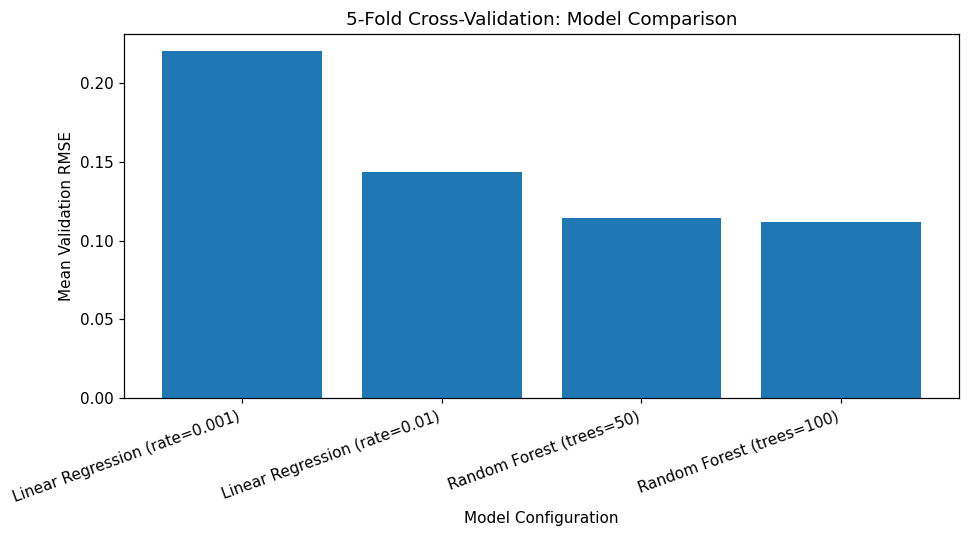

In [12]:


iterations = 10000

number_of_folds = 5

fold_indices = np.array_split(
    np.random.permutation(len(x_train_raw)),
    number_of_folds
)

lr_001_scores = []
lr_01_scores = []
rf_50_scores = []
rf_100_scores = []

for fold in range(number_of_folds):

    validation_indices = fold_indices[fold]

    training_indices = np.concatenate([
        fold_indices[i]
        for i in range(number_of_folds)
        if i != fold
    ])

    fold_x_train_raw = x_train_raw.iloc[training_indices].copy()
    fold_x_valid_raw = x_train_raw.iloc[validation_indices].copy()

    fold_y_train = y_train[training_indices]
    fold_y_valid = y_train[validation_indices]

    (
        fold_x_train_encoded,
        fold_x_valid_encoded,
        fold_x_train_lr,
        fold_x_valid_lr
    ) = prepare_features(
        fold_x_train_raw,
        fold_x_valid_raw
    )

    fold_x_train_array = fold_x_train_lr.to_numpy(dtype=float)
    fold_x_valid_array = fold_x_valid_lr.to_numpy(dtype=float)

    weights = fit_lr(
        fold_x_train_array,
        fold_y_train,
        0.001,
        iterations
    )

    predictions = calc_preds(
        fold_x_valid_array,
        weights
    )

    lr_001_scores.append(
        calc_metrics(fold_y_valid, predictions)
    )

    weights = fit_lr(
        fold_x_train_array,
        fold_y_train,
        0.01,
        iterations
    )

    predictions = calc_preds(
        fold_x_valid_array,
        weights
    )

    lr_01_scores.append(
        calc_metrics(fold_y_valid, predictions)
    )

    rf_model = RandomForestRegressor(
        n_estimators=50,
        random_state=random_seed
    )

    rf_model.fit(
        fold_x_train_encoded,
        fold_y_train
    )

    predictions = rf_model.predict(
        fold_x_valid_encoded
    )

    rf_50_scores.append(
        calc_metrics(fold_y_valid, predictions)
    )

    rf_model = RandomForestRegressor(
        n_estimators=100,
        random_state=random_seed
    )

    rf_model.fit(
        fold_x_train_encoded,
        fold_y_train
    )

    predictions = rf_model.predict(
        fold_x_valid_encoded
    )

    rf_100_scores.append(
        calc_metrics(fold_y_valid, predictions)
    )


metric_names = ["MAE", "MSE", "RMSE", "R2"]

cv_results = pd.DataFrame(
    [
        np.mean(lr_001_scores, axis=0),
        np.mean(lr_01_scores, axis=0),
        np.mean(rf_50_scores, axis=0),
        np.mean(rf_100_scores, axis=0)
    ],
    columns=metric_names,
    index=[
        "Linear Regression (rate=0.001)",
        "Linear Regression (rate=0.01)",
        "Random Forest (trees=50)",
        "Random Forest (trees=100)"
    ]
)

print("5-FOLD CROSS-VALIDATION RESULTS")
print(cv_results.round(4))

plt.figure(figsize=(9, 5))

plt.bar(
    cv_results.index,
    cv_results["RMSE"]
)

plt.title("5-Fold Cross-Validation: Model Comparison")
plt.xlabel("Model Configuration")
plt.ylabel("Mean Validation RMSE")

plt.xticks(rotation=20, ha="right")
plt.tight_layout()
plt.show()


### Select the configuration with the lowest validation RMSE

The test set is not used for this decision.

In [13]:
best_configuration = cv_results["RMSE"].idxmin()

print("\nSelected configuration:")
print(best_configuration)

learning_rate = 0.01
best_trees = 100
rf_model = RandomForestRegressor(
    n_estimators=best_trees,
    random_state=random_seed
)

if best_configuration == "Linear Regression (rate=0.001)":

    selected_model = "Linear Regression"
    learning_rate = 0.001

elif best_configuration == "Linear Regression (rate=0.01)":

    selected_model = "Linear Regression"
    learning_rate = 0.01

elif best_configuration == "Random Forest (trees=50)":

    selected_model = "Random Forest"
    best_trees = 50

else:

    selected_model = "Random Forest"
    best_trees = 100


print("\nSelected model:", selected_model)



Selected configuration:
Random Forest (trees=100)

Selected model: Random Forest


## 10. Final evaluation on the reserved test set

After selecting one configuration, train it with the complete training set and evaluate it on the test set. These test results are not used to change the model selection.

In [14]:

x_train_encoded, x_test_encoded, x_train_lr, x_test_lr = prepare_features(
    x_train_raw,
    x_test_raw
)

if selected_model == "Linear Regression":

    x_train_array = x_train_lr.to_numpy(dtype=float)
    x_test_array = x_test_lr.to_numpy(dtype=float)

    weights = fit_lr(
        x_train_array,
        y_train,
        learning_rate,
        iterations
    )

    y_train_pred_final = calc_preds(
        x_train_array,
        weights
    )

    y_pred_final = calc_preds(
        x_test_array,
        weights
    )

else:

    rf_model = RandomForestRegressor(
        n_estimators=best_trees,
        random_state=random_seed
    )

    rf_model.fit(
        x_train_encoded,
        y_train
    )

    y_train_pred_final = rf_model.predict(
        x_train_encoded
    )

    y_pred_final = rf_model.predict(
        x_test_encoded
    )


train_metrics_final = calc_metrics(
    y_train,
    y_train_pred_final
)

test_metrics_final = calc_metrics(
    y_test,
    y_pred_final
)

final_results = pd.DataFrame(
    [
        train_metrics_final,
        test_metrics_final
    ],
    columns=metric_names,
    index=["Training", "Test"]
)

print("\nFINAL MODEL RESULTS")
print(final_results.round(4))

print("\nFirst test predictions:")
print(y_pred_final[:10])

print("\nCorresponding actual values:")
print(y_test[:10])



FINAL MODEL RESULTS
             MAE     MSE    RMSE      R2
Training  0.0231  0.0020  0.0449  0.9974
Test      0.0506  0.0098  0.0992  0.9865

First test predictions:
[1.3761 4.2165 2.826  2.007  2.854  3.674  1.9    4.23   1.557  3.    ]

Corresponding actual values:
[1.4 4.2 2.8 2.  2.8 3.6 1.9 4.2 1.8 3. ]


## 11. Actual vs predicted procrastination scores

Points closer to the diagonal reference line indicate predictions closer to the actual test scores.

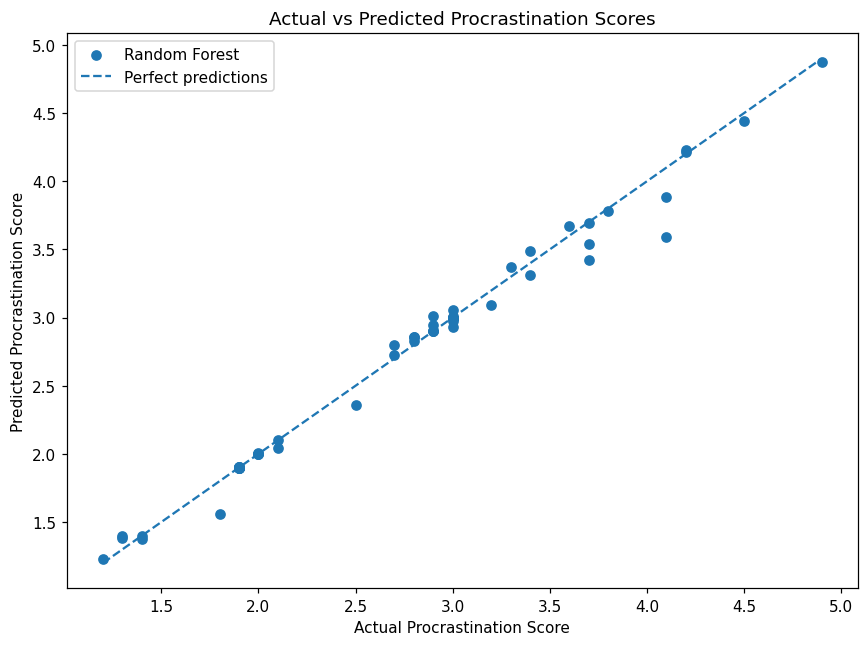

In [15]:


minimum = min(
    y_test.min(),
    y_pred_final.min()
)

maximum = max(
    y_test.max(),
    y_pred_final.max()
)

plt.figure(figsize=(8, 6))

plt.scatter(
    y_test,
    y_pred_final,
    label=selected_model
)

plt.plot(
    [minimum, maximum],
    [minimum, maximum],
    linestyle="--",
    label="Perfect predictions"
)

plt.title("Actual vs Predicted Procrastination Scores")
plt.xlabel("Actual Procrastination Score")
plt.ylabel("Predicted Procrastination Score")

plt.legend()
plt.tight_layout()
plt.show()


## 12. Random Forest feature importance

This plot is displayed only if Random Forest is selected. Feature importance describes how the trained forest used features for its splits; it does not demonstrate causation.

Top 10 features:
perceived_control                           0.6057
concentration_difficulty                    0.2362
feeling_overwhelmed_frequency               0.0304
work_life_balance                           0.0268
stress_rating                               0.0266
social_media_as_task_avoidance              0.0151
social_media_during_work_or_study_Always    0.0134
mood_rating                                 0.0079
daily_screen_time_hours                     0.0071
energy_rating                               0.0062
dtype: float64


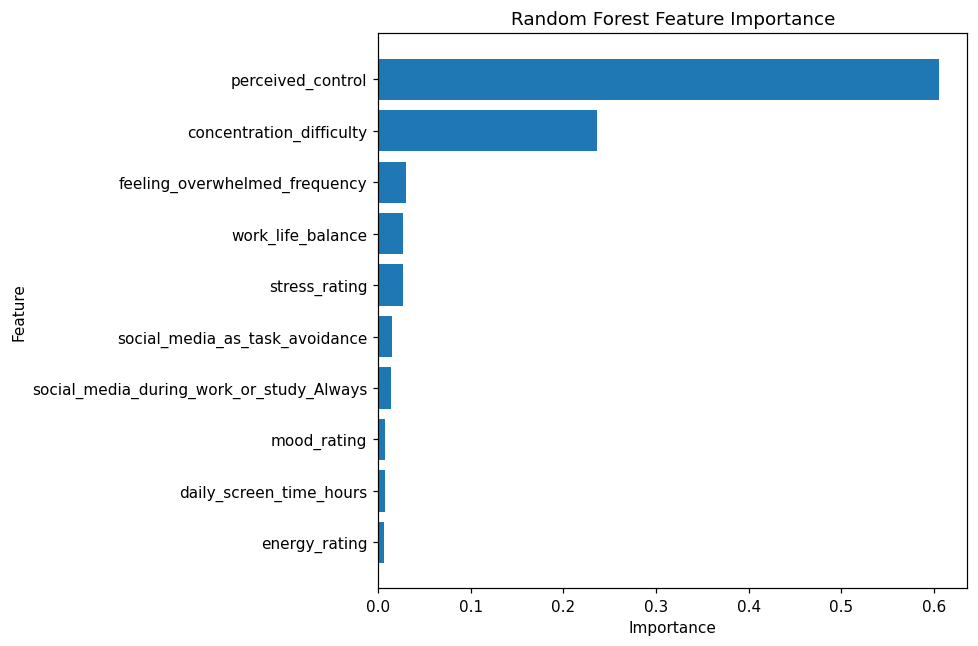

In [16]:


if selected_model == "Random Forest":

    feature_importance = pd.Series(
        rf_model.feature_importances_,
        index=x_train_encoded.columns
    )

    feature_importance = feature_importance.sort_values()

    top_features = feature_importance.tail(10)

    print("Top 10 features:")
    print(top_features.sort_values(ascending=False).round(4))

    feature_values = top_features.to_numpy(dtype=float)
    feature_names = top_features.index.tolist()

    plt.figure(figsize=(9, 6))

    plt.barh(
        feature_names,
        feature_values
    )

    plt.title("Random Forest Feature Importance")
    plt.xlabel("Importance")
    plt.ylabel("Feature")

    plt.tight_layout()
    plt.show()


## Conclusion

The selected configuration is the one with the lowest mean validation RMSE. The final test metrics evaluate that configuration on observations held out from both training and model selection.

A fixed random seed is used to make the train/test split, cross-validation folds and Random Forest training reproducible under the same software environment.